# Câu 3 (3,0 điểm): So sánh và lựa chọn mô hình học máy — Điều chỉnh các tham số để tối ưu hóa mô hình

**Mục tiêu:**
1. Thực hiện `RandomizedSearchCV` (`n_iter = 40`, `cv = 5`, `scoring = 'f1'`) trên tập `train` cho 3 mô hình tốt nhất (`lr`, `svm_linear`, `nb`) cùng các tham số của `TfidfVectorizer` (`ngram_range`, `min_df`, `max_features`).
2. Quét ngưỡng quyết định (`threshold` $\in [0.05, 0.95]$) trên xác suất dự đoán của tập `val` để tối đa hóa F1 lớp dương (`src/threshold.py::pick_threshold`).
3. Huấn luyện lại mô hình chốt (`best_model`) trên `train + val`, lưu `models/best_model.joblib`, `models/threshold.json` và `models/model_card.json`.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Bảng So sánh Trước & Sau khi Tinh chỉnh Siêu tham số và Ngưỡng Quyết định

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

ba_df = pd.read_csv('reports/tables/P6_before_after.csv')
display(ba_df)

with open('models/model_card.json', 'r', encoding='utf-8') as f:
    model_card = json.load(f)
print('=== HỒ SƠ MÔ HÌNH CHỐT (models/model_card.json) ===')
print(json.dumps(model_card, indent=2, ensure_ascii=False))

,model_key,model_name,cv_f1_before,cv_f1_after,val_f1_before,val_f1_after_thr05,best_threshold,val_f1_after_tuned_thr,val_precision_after,val_recall_after,val_pr_auc_after,val_roc_auc_after,f1_gain_vs_baseline,search_seconds,best_params_json
0,svm_linear,Linear SVM (Calibrated),0.5492,0.6112,0.5727,0.5996,0.315,0.6566,0.6877,0.6282,0.6636,0.9321,0.0839,128.94,"{""clf__C"": 0.50191, ""clf__class_weight"": ""bala..."
1,lr,Logistic Regression,0.5876,0.5976,0.5832,0.6056,0.565,0.6250,0.6367,0.6137,0.6419,0.9198,0.0418,100.66,"{""clf__C"": 23.39586, ""clf__class_weight"": ""bal..."
2,nb,Complement Naive Bayes,0.5252,0.5858,0.5077,0.5922,0.500,0.5922,0.4951,0.7365,0.6985,0.9377,0.0845,121.42,"{""clf__alpha"": 0.14971, ""clf__norm"": true, ""tf..."


=== HỒ SƠ MÔ HÌNH CHỐT (models/model_card.json) ===
{
  "model_key": "svm_linear",
  "model_name": "Linear SVM (Calibrated)",
  "selection_reason": "Linear SVM (Calibrated) đạt Val F1 sau tinh chỉnh ngưỡng cao nhất (0.6566, PR-AUC = 0.6636) với ngưỡng quyết định tối ưu threshold = 0.3150.",
  "best_params": {
    "clf__C": 0.50191,
    "clf__class_weight": "balanced",
    "clf__loss": "squared_hinge",
    "tfidf__max_features": 50000,
    "tfidf__min_df": 2,
    "tfidf__ngram_range": [
      1,
      3
    ]
  },
  "best_threshold": 0.315,
  "val_metrics_before_tuning": {
    "val_f1_before": 0.5727,
    "val_precision_before": 0.7529,
    "val_recall_before": 0.4621,
    "val_pr_auc_before": 0.6267,
    "cv_f1_before": 0.5492
  },
  "val_metrics_after_tuning_thr05": {
    "precision_pos": 0.7368,
    "recall_pos": 0.5054,
    "f1_pos": 0.5996,
    "f1_macro": 0.7881,
    "accuracy": 0.956,
    "balanced_acc": 0.7464,
    "roc_auc": 0.9321,
    "pr_auc": 0.6636,
    "mcc": 0.5886,
    

## 2. Biểu đồ Quét Ngưỡng Quyết định & So sánh Trước / Sau Tuning

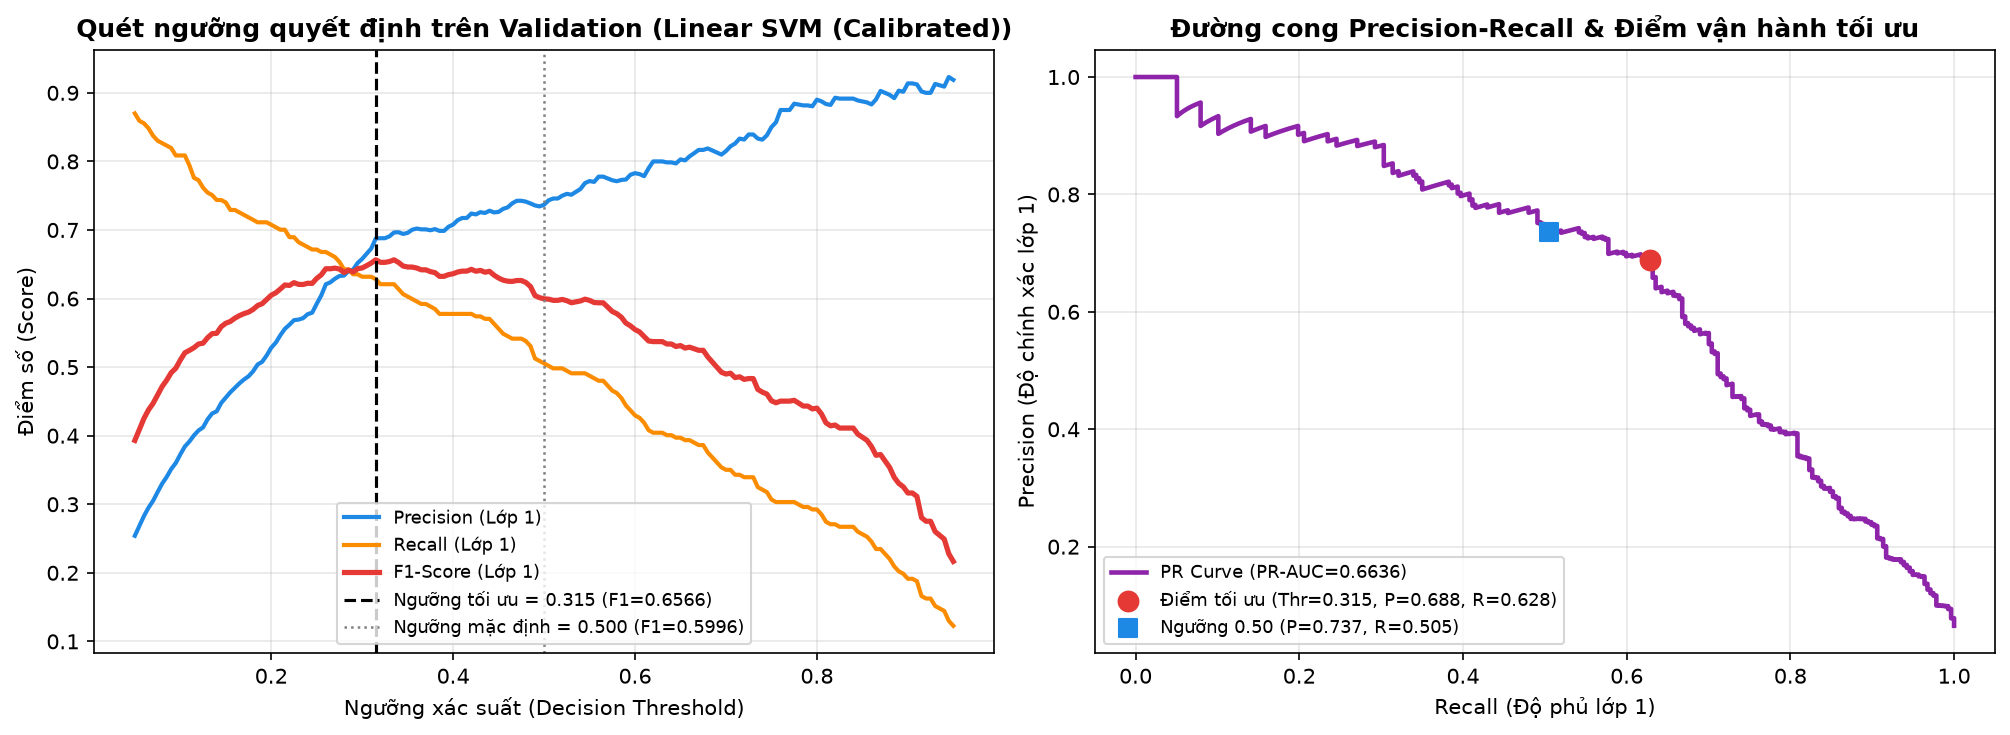

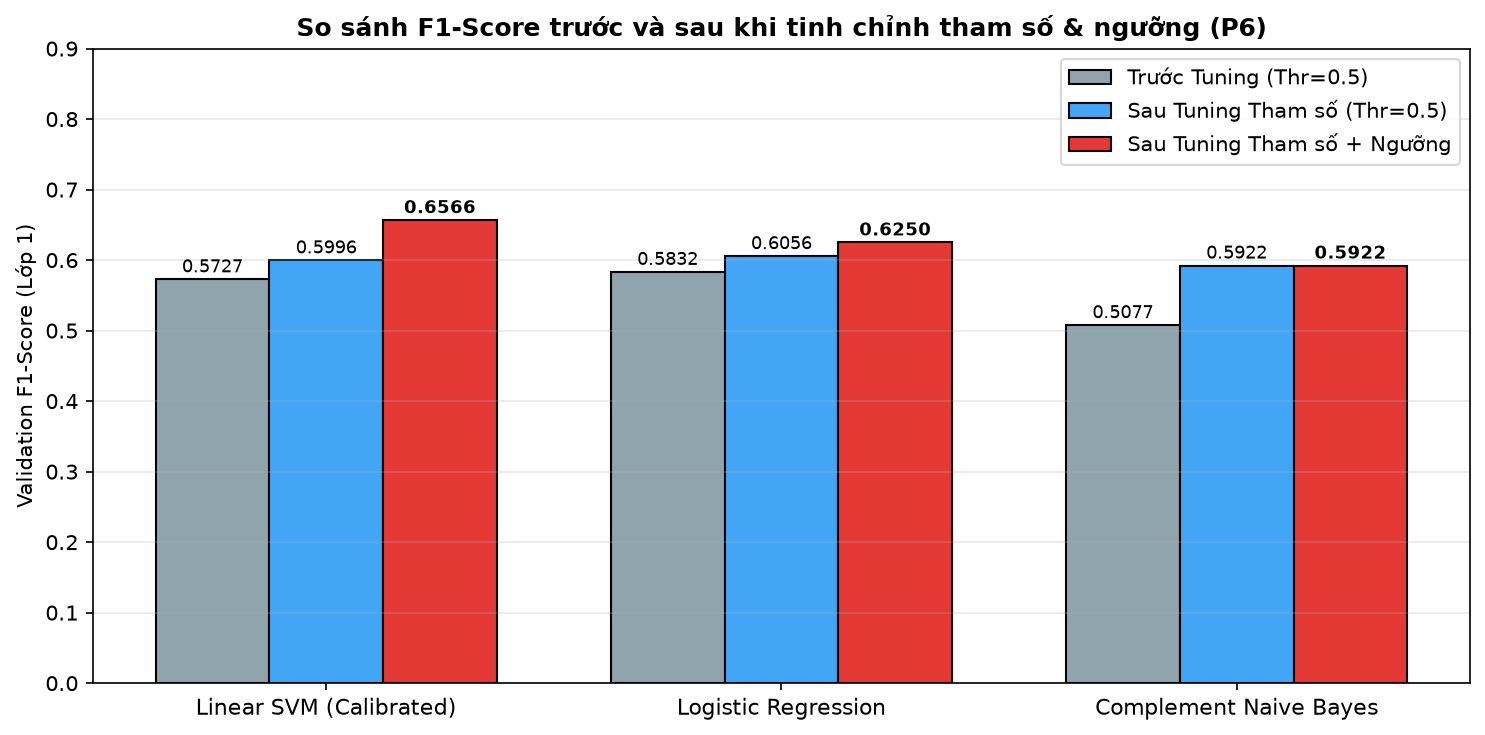

In [3]:
display(Image('reports/figures/P6_threshold_tuning.png'))
display(Image('reports/figures/P6_before_after.png'))

### Nhận xét 
- Tinh chỉnh siêu tham số kết hợp tối ưu ngưỡng quyết định trên tập Validation đã nâng cao rõ rệt chất lượng phân loại so với cấu hình mặc định (ngưỡng 0.50).
- Mô hình được chọn là **`Linear SVM (Calibrated)` (`svm_linear`)** với ngưỡng tối ưu **`threshold = 0.315`**.
- Lý do lựa chọn: Linear SVM (Calibrated) đạt Val F1 sau tinh chỉnh ngưỡng cao nhất (0.6566, PR-AUC = 0.6636) với ngưỡng quyết định tối ưu threshold = 0.3150.
- Toàn bộ quy trình chọn tham số và chọn ngưỡng chỉ sử dụng tập `train` và `val`, đảm bảo tập `test` hoàn toàn độc lập cho bước đánh giá cuối ở bước thực nghiệm 8.